<a href="https://colab.research.google.com/github/bhargavanarasimhaai24/BitByBit-Leetcode/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Identifying Influential Points

**Topic:** Regression diagnostics and influential observations

## Aim

Fit an ordinary least squares (OLS) regression model and use residual and influence diagnostics to identify observations that may have an unusually large effect on the fitted model.

## Learning objectives

- Fit and summarize a multiple linear regression model.
- Inspect residuals using a residual-versus-fitted plot and a normal Q–Q plot.
- Calculate and visualize Cook's distance, leverage, DFFITS, and DFBETAS.
- Flag observations for further investigation without automatically deleting them.

> **Dataset note:** This notebook expects the original `Patient.csv` file. The uploaded notebook did not contain that CSV, so it is not included here. See the repository README for the expected location and columns.

## Workflow

1. Load and validate the data.
2. Fit the regression model for **Satisfaction** using **Age** and **Severity** as predictors.
3. Review residual diagnostics.
4. Calculate influence measures and compare them with common screening guidelines.
5. Inspect flagged observations and document a conclusion.

The columns `Surg-Med` and `Anxiety`, if present in the CSV, are not used in this model because the original analysis selected `Age` and `Severity` as predictors.

## 1. Import libraries and load the data

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.graphics.regressionplots import plot_leverage_resid2
from statsmodels.stats.outliers_influence import OLSInfluence

In [ ]:
data = pd.read_csv('Patient.csv')

required_columns = ["Age", "Severity", "Satisfaction"]

print(f"Rows: {data.shape[0]} | Columns: {data.shape[1]}")
display(data.head())

Rows: 25 | Columns: 5


,Age,Severity,Surg-Med,Anxiety,Satisfaction
0,55,50,0,2.1,68
1,46,24,1,2.8,77
2,30,46,1,3.3,96
3,35,48,1,4.5,80
4,59,58,0,2.0,43


## 2. Specify and fit the regression model

The response variable is `Satisfaction`. The predictors are `Age` and `Severity`. A constant column is added so that the model estimates an intercept.

In [ ]:
X = data[["Age", "Severity"]]
y = data["Satisfaction"]

X = sm.add_constant(X, has_constant="add")

model = sm.OLS(y, X, missing="raise").fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Satisfaction   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.887
Method:                 Least Squares   F-statistic:                     95.38
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           1.45e-11
Time:                        16:42:12   Log-Likelihood:                -82.940
No. Observations:                  25   AIC:                             171.9
Df Residuals:                      22   BIC:                             175.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        143.4720      5.955     24.093      0.0

### Model summary

Review the coefficient estimates, p-values, and goodness-of-fit statistics. The summary describes the fitted model; influence diagnostics below help assess whether individual observations may have an outsized effect on those estimates.

## 3. Residual diagnostics

Residual plots help assess model assumptions and reveal observations that the fitted model does not explain well. They should be interpreted alongside subject-matter knowledge and other diagnostics.

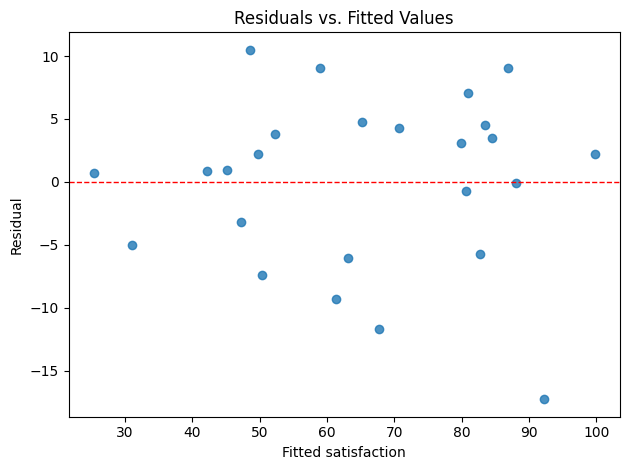

In [ ]:
# Residuals versus fitted values
fig, ax = plt.subplots()
ax.scatter(model.fittedvalues, model.resid, alpha=0.8)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Fitted satisfaction")
ax.set_ylabel("Residual")
ax.set_title("Residuals vs. Fitted Values")
plt.tight_layout()
plt.show()

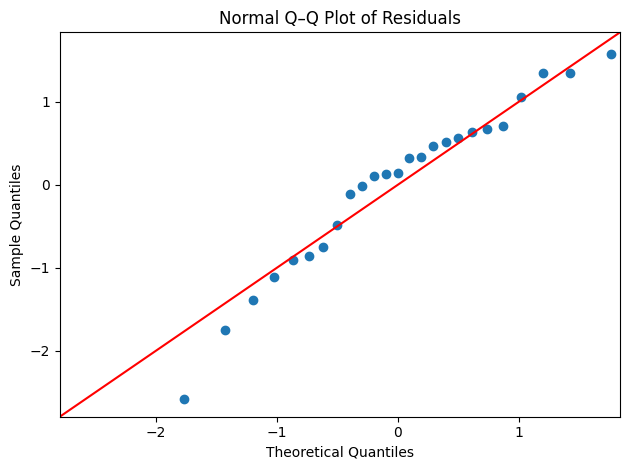

In [ ]:
# Normal Q–Q plot of the model residuals
sm.qqplot(model.resid, line="45", fit=True)
plt.title("Normal Q–Q Plot of Residuals")
plt.tight_layout()
plt.show()

**How to read the Q–Q plot:** points close to the reference line are consistent with approximately normal *residuals*. Strong curvature or substantial departures in the tails may indicate non-normality. The plot does not test whether the predictor variables themselves are normally distributed.

## 4. Calculate influence measures

The measures below capture different aspects of a data point's influence:

- **Cook's distance:** overall change in the fitted model when an observation is omitted.
- **Leverage:** how unusual an observation's predictor values are relative to the rest of the data.
- **DFFITS:** change in the fitted value for an observation when it is omitted.
- **DFBETAS:** change in each regression coefficient when an observation is omitted.

No single measure is definitive. The thresholds used below are common screening guidelines, not strict statistical laws.

In [ ]:
influence = OLSInfluence(model)

n = int(model.nobs)
k = len(model.params)  # Number of estimated parameters, including the intercept
observation = np.arange(1, n + 1)

cooks_distance = influence.cooks_distance[0]
leverage = influence.hat_matrix_diag
dffits = influence.dffits[0]
dfbetas = influence.dfbetas

# Common heuristic cutoffs for screening potentially influential observations.
cook_cutoff = 4 / n
leverage_cutoff = 2 * k / n
dffits_cutoff = 2 * np.sqrt(k / n)
dfbetas_cutoff = 2 / np.sqrt(n)

diagnostics = pd.DataFrame({
    "Observation": observation,
    "Fitted value": np.asarray(model.fittedvalues),
    "Residual": np.asarray(model.resid),
    "Externally studentized residual": influence.resid_studentized_external,
    "Leverage": leverage,
    "Cook's distance": cooks_distance,
    "DFFITS": dffits,
    "Maximum absolute DFBETAS": np.max(np.abs(dfbetas), axis=1),
})

print(f"Number of observations (n): {n}")
print(f"Number of estimated parameters, including intercept (k): {k}")
print(f"Cook's distance guideline: {cook_cutoff:.4f}")
print(f"Leverage guideline: {leverage_cutoff:.4f}")
print(f"Absolute DFFITS guideline: {dffits_cutoff:.4f}")
print(f"Absolute DFBETAS guideline: {dfbetas_cutoff:.4f}")

display(
    diagnostics.sort_values("Cook's distance", ascending=False)
    .head(10)
    .round(4)
    .reset_index(drop=True)
)

Number of observations (n): 25
Number of estimated parameters, including intercept (k): 3
Cook's distance guideline: 0.1600
Leverage guideline: 0.2400
Absolute DFFITS guideline: 0.6928
Absolute DFBETAS guideline: 0.4000


,Observation,Fitted value,Residual,Externally studentized residual,Leverage,Cook's distance,DFFITS,Maximum absolute DFBETAS
0,9,92.2800,-17.2800,-3.1512,0.1655,0.4670,-1.4035,1.2037
1,23,61.2785,-9.2785,-1.5112,0.2125,0.1940,-0.7849,0.6470
2,21,48.5007,10.4993,1.6913,0.1750,0.1865,0.7790,0.6690
3,3,86.9627,9.0373,1.4122,0.1551,0.1168,0.6051,0.5213
4,11,67.6967,-11.6967,-1.7848,0.0680,0.0705,-0.4823,0.3047
5,2,82.6986,-5.6986,-0.8775,0.1763,0.0555,-0.4060,0.3511
6,7,31.0316,-5.0316,-0.7665,0.1654,0.0396,-0.3412,0.2474
7,5,50.3897,-7.3897,-1.0844,0.0760,0.0320,-0.3111,0.1725
8,8,80.9384,7.0616,1.0318,0.0728,0.0278,0.2890,0.1901
9,1,58.9622,9.0378,1.3211,0.0449,0.0264,0.2863,0.0535


## 5. Cook's distance

Observations with Cook's distance above the dashed guideline deserve closer inspection. A point below the guideline can still matter, and a point above it should not be removed automatically.

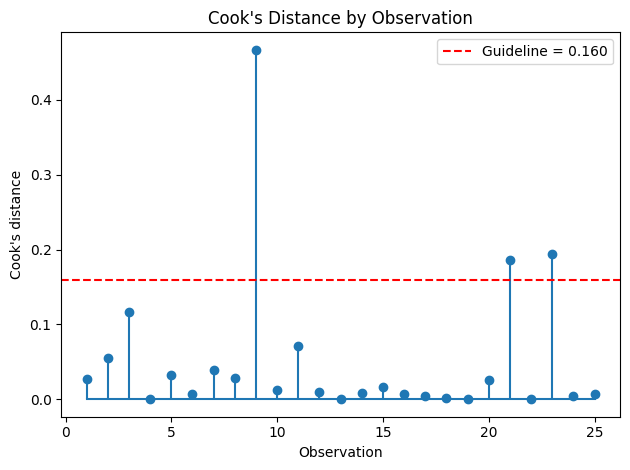

In [ ]:
fig, ax = plt.subplots()
ax.stem(observation, cooks_distance, basefmt="-")
ax.axhline(cook_cutoff, color="red", linestyle="--", label=f"Guideline = {cook_cutoff:.3f}")
ax.set_xlabel("Observation")
ax.set_ylabel("Cook's distance")
ax.set_title("Cook's Distance by Observation")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Leverage and residuals

High leverage indicates an unusual combination of predictor values. The leverage-versus-residual plot helps distinguish observations with unusual predictor values from observations with large residuals.

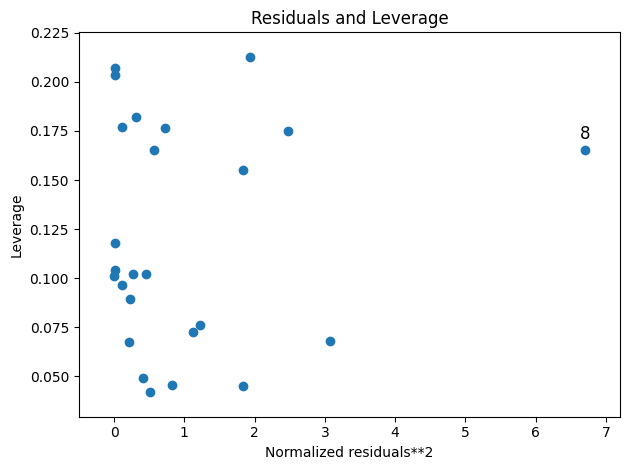

In [ ]:
plot_leverage_resid2(model)
plt.title("Residuals and Leverage")
plt.tight_layout()
plt.show()

## 7. DFFITS

The plot marks observations whose absolute DFFITS exceeds the screening guideline.

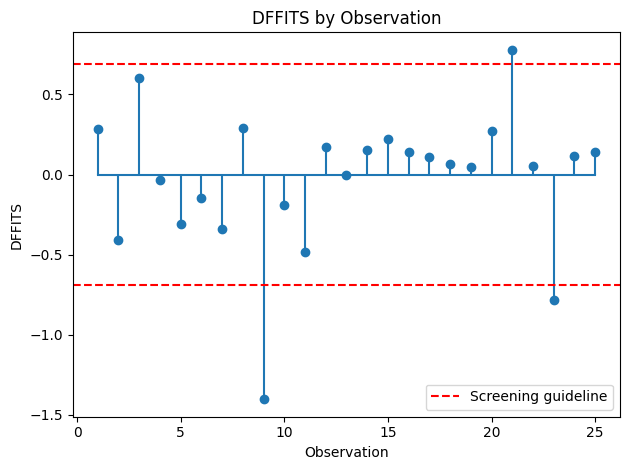

In [ ]:
fig, ax = plt.subplots()
ax.stem(observation, dffits, basefmt="-")
ax.axhline(dffits_cutoff, color="red", linestyle="--", label="Screening guideline")
ax.axhline(-dffits_cutoff, color="red", linestyle="--")
ax.set_xlabel("Observation")
ax.set_ylabel("DFFITS")
ax.set_title("DFFITS by Observation")
ax.legend()
plt.tight_layout()
plt.show()

## 8. DFBETAS

Each panel shows how strongly an observation affects one estimated coefficient. Both positive and negative departures are relevant.

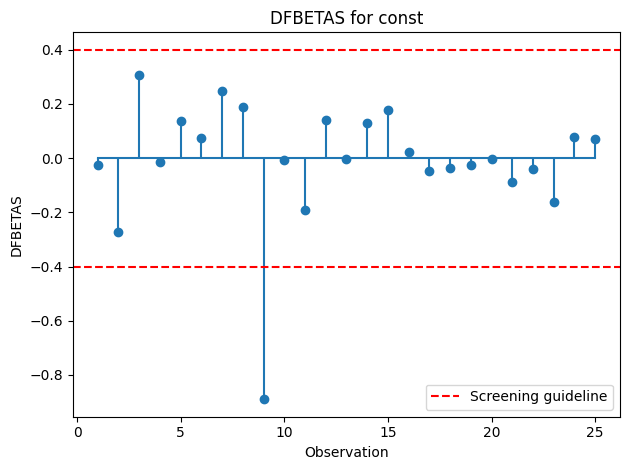

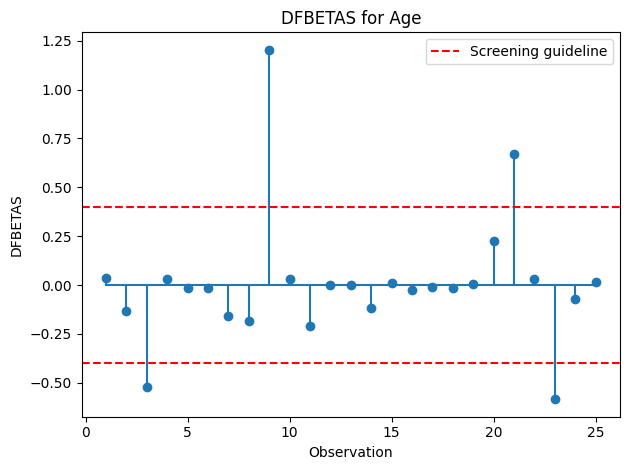

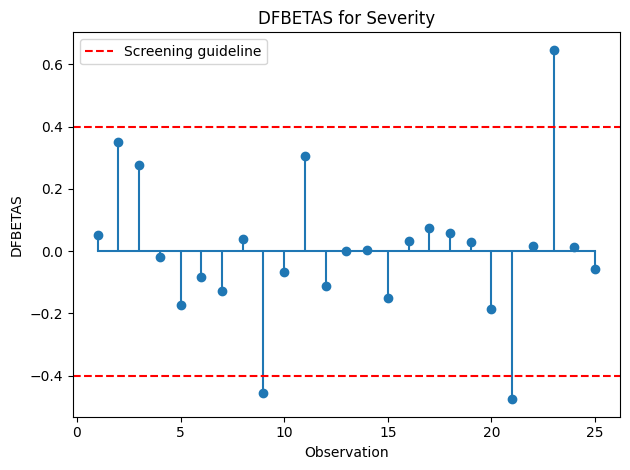

In [ ]:
for column_index, parameter_name in enumerate(model.params.index):
    fig, ax = plt.subplots()
    ax.stem(observation, dfbetas[:, column_index], basefmt="-")
    ax.axhline(dfbetas_cutoff, color="red", linestyle="--", label="Screening guideline")
    ax.axhline(-dfbetas_cutoff, color="red", linestyle="--")
    ax.set_xlabel("Observation")
    ax.set_ylabel("DFBETAS")
    ax.set_title(f"DFBETAS for {parameter_name}")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 9. Leverage values

The dashed line is a common screening guideline based on the number of estimated parameters and observations.

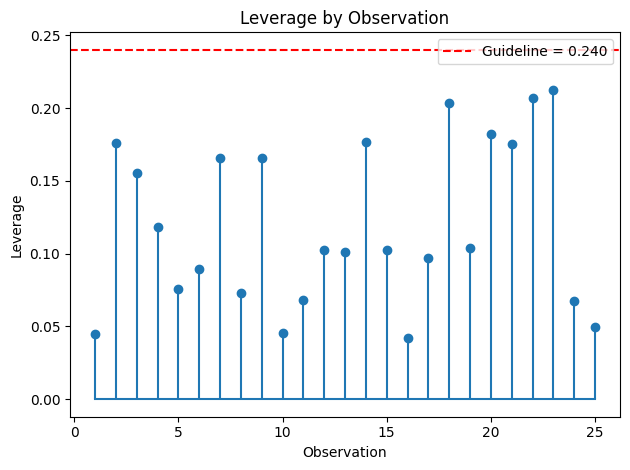

In [ ]:
fig, ax = plt.subplots()
ax.stem(observation, leverage, basefmt="-")
ax.axhline(leverage_cutoff, color="red", linestyle="--", label=f"Guideline = {leverage_cutoff:.3f}")
ax.set_xlabel("Observation")
ax.set_ylabel("Leverage")
ax.set_title("Leverage by Observation")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Flag observations for review

The following table flags any observation that crosses at least one of the heuristic cutoffs. These are **candidates for investigation**, not automatic reasons for deletion.

In [ ]:
diagnostics["High Cook's distance"] = diagnostics["Cook's distance"] > cook_cutoff
diagnostics["High leverage"] = diagnostics["Leverage"] > leverage_cutoff
diagnostics["High absolute DFFITS"] = diagnostics["DFFITS"].abs() > dffits_cutoff
diagnostics["High absolute DFBETAS"] = (
    diagnostics["Maximum absolute DFBETAS"] > dfbetas_cutoff
)

flag_columns = [
    "High Cook's distance",
    "High leverage",
    "High absolute DFFITS",
    "High absolute DFBETAS",
]
diagnostics["Flagged for review"] = diagnostics[flag_columns].any(axis=1)

candidates = diagnostics.loc[diagnostics["Flagged for review"]].copy()
if candidates.empty:
    print("No observations crossed the selected screening guidelines.")
else:
    display(
        candidates.sort_values("Cook's distance", ascending=False)
        .round(4)
        .reset_index(drop=True)
    )

,Observation,Fitted value,Residual,Externally studentized residual,Leverage,Cook's distance,DFFITS,Maximum absolute DFBETAS,High Cook's distance,High leverage,High absolute DFFITS,High absolute DFBETAS,Flagged for review
0,9,92.2800,-17.2800,-3.1512,0.1655,0.4670,-1.4035,1.2037,True,False,True,True,True
1,23,61.2785,-9.2785,-1.5112,0.2125,0.1940,-0.7849,0.6470,True,False,True,True,True
2,21,48.5007,10.4993,1.6913,0.1750,0.1865,0.7790,0.6690,True,False,True,True,True
3,3,86.9627,9.0373,1.4122,0.1551,0.1168,0.6051,0.5213,False,False,False,True,True


## 11. Analysis of the supplied results

> **Reference-run note:** The interpretation below is based on the accompanying **OLS Regression Results** report. The original `Patient.csv` was not included with the uploaded files, so these reported numbers cannot be regenerated in this environment. When you run the notebook with your own copy of `Patient.csv`, use the newly generated output if it differs from these reference results.

### 11.1 Model fit and coefficient interpretation

The reported model uses 25 observations and estimates **Satisfaction** from **Age** and **Severity**:

\[
$\widehat{\text{Satisfaction}}$ = 143.472 - 1.0311  ($\text{Age}$) - 0.5560   ($\text{Severity}$)
\]

| Result | Reported value | Interpretation |
|---|---:|---|
| R-squared | 0.897 | The model accounts for 89.7% of the observed variation in Satisfaction in this sample. |
| Adjusted R-squared | 0.887 | The fit remains high after accounting for the number of predictors. |
| F-statistic | 95.38 | The model is statistically significant overall. |
| Prob(F-statistic) | 1.45e-11 | Strong evidence that the predictor coefficients are not jointly zero. |
| Age coefficient | -1.0311; p < 0.001 | Holding Severity constant, one additional unit of Age is associated with an estimated 1.031-point lower Satisfaction. The 95% confidence interval is [-1.271, -0.791]. |
| Severity coefficient | -0.5560; p < 0.001 | Holding Age constant, one additional unit of Severity is associated with an estimated 0.556-point lower Satisfaction. The 95% confidence interval is [-0.829, -0.284]. |

Both predictor coefficients are negative and statistically significant in the reported model. These are **associations**, not evidence that age or severity causes the change in satisfaction. The intercept (143.472) is the model's predicted response when both predictors equal zero; that value may not have a useful real-world interpretation if zero is outside the meaningful range of the predictors.

### 11.2 Residual diagnostics

- **Residuals versus fitted values:** The residuals are distributed on both sides of zero, with no obvious strong curved pattern in the supplied plot. However, observation 9 has a notably large negative residual (-17.280), so it warrants checking. A plot of 25 observations alone cannot establish that all model assumptions hold.
- **Normal Q–Q plot:** Most points lie reasonably close to the reference line, while the lower tail shows a noticeable departure. This is consistent with the unusually negative studentized residual for observation 9.
- **Normality tests:** The reported Omnibus p-value is 0.232 and Jarque–Bera p-value is 0.373. Neither test rejects residual normality at the 5% level, but with only 25 observations these tests have limited power; consider the plots and influence diagnostics as well.
- **Durbin–Watson:** The reported value is 1.934, which is close to 2 and does not suggest strong residual autocorrelation by itself. Its interpretation depends on whether the observation order has meaningful sequencing.

### 11.3 Influential observations

For the reported run, there are 25 observations and 3 estimated parameters (including the intercept). The screening guidelines used in the notebook are:

| Measure | Screening guideline |
|---|---:|
| Cook's distance | \(4/n = 0.160\) |
| Leverage | \(2k/n = 0.240\) |
| Absolute DFFITS | \(2\sqrt{k/n} \approx 0.693\) |
| Maximum absolute DFBETAS | \(2/\sqrt{n} = 0.400\) |

The supplied influence table identifies the following cases:

| Observation | Fitted value | Residual | External studentized residual | Leverage | Cook's distance | DFFITS | Maximum absolute DFBETAS | Measures exceeding guideline |
|---:|---:|---:|---:|---:|---:|---:|---:|---|
| 9 | 92.2800 | -17.2800 | -3.1512 | 0.1655 | 0.4670 | -1.4035 | 1.2037 | Cook's distance, absolute DFFITS, absolute DFBETAS; also has a large studentized residual |
| 23 | 61.2785 | -9.2785 | -1.5112 | 0.2125 | 0.1940 | -0.7849 | 0.6470 | Cook's distance, absolute DFFITS, absolute DFBETAS |
| 21 | 48.5007 | 10.4993 | 1.6913 | 0.1750 | 0.1865 | 0.7790 | 0.6690 | Cook's distance, absolute DFFITS, absolute DFBETAS |
| 3 | 86.9627 | 9.0373 | 1.4122 | 0.1551 | 0.1168 | 0.6051 | 0.5213 | Absolute DFBETAS only, among these four measures |

**Main finding:** Observation 9 is the highest-priority case. Its externally studentized residual (-3.1512) is unusually large in magnitude, and its Cook's distance, DFFITS, and DFBETAS all exceed their screening guidelines. Observations 23 and 21 are also flagged by these three influence measures. Observation 3 is flagged because its maximum absolute DFBETAS exceeds 0.400, even though its Cook's distance and absolute DFFITS are below their respective cutoffs.

None of these four observations exceeds the leverage guideline of 0.240. A point can still be influential without exceeding a leverage threshold, because influence depends on the combination of predictor location and residual size. Note that the diagnostic table labels observations from 1 to 25, whereas the statsmodels leverage-residual plot may annotate the ninth row as index **8** because it uses zero-based indexing; these refer to the same row when the CSV has its default row index.

### 11.4 What to do next

1. Inspect the original records for observations 9, 23, 21, and 3 for data-entry or measurement errors.
2. Confirm whether each record is valid and representative of the population; do not remove a valid case simply because a diagnostic threshold is exceeded.
3. Refit the model with and without the highest-priority case(s) as a **sensitivity analysis**, then compare coefficients, confidence intervals, and conclusions. Document any exclusion and its justification.
4. Report that the findings come from a small sample (n = 25) and interpret the estimated relationships with appropriate caution.

These cutoffs are screening heuristics, not automatic deletion rules.

## 12. Conclusion and reporting notes

After running the notebook, summarize the results in your lab report:

1. State the fitted regression model and briefly comment on the residual plots.
2. Identify observations flagged by one or more influence measures.
3. Explain which measures flagged each observation and whether the evidence agrees across measures.
4. Check flagged records for data-entry errors, unusual but valid cases, or omitted explanatory variables.
5. If appropriate, compare the model with and without a flagged observation and report how the estimates change.

**Important:** do not delete observations solely because they exceed a heuristic threshold. Record the reason for any exclusion and report whether the conclusions change.